<a href="https://colab.research.google.com/github/PauloSBLima/vision-auto-check/blob/main/train_bbox.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
INÍCIO

## 👓 Sobre
## Projeto: <font size="10">🚗</font> <font color="orange">**VisionAutoCheck (VAC)**</font>
## &emsp;&emsp;&emsp;&emsp;&emsp;&nbsp;&nbsp;&nbsp; Sistema Inteligente de Detecção para Oficina Automotiva
<font color="yellow">Método: Bounding Boxes</font>

## 1️⃣ 1.0 Módulo de Detecção das Imagens do Modelo

Sugere-se a utilização do <font color="#FFA500">*`Google Colab com recursos de GPU Tesla T4`*</font>.<br>
Este notebook foi elaborado para servir de modelo de aprendizado, por isso, várias células do tipo "Markdown" foram
utilizadas com o intuito de enriquecer este material.<br>
<font color="#32CD32">Sugerimos o uso do tema "Dark"</font> para uma melhor visualização das saídas. Fique à vontade para contribuir. <mark>Bom uso! 👌</mark>

---
## ⚙ 0.0 Preparação do Ambiente Google Colab

In [ ]:
import os                           # Módulo para interações com o sistema operacional (ex: manipulação de diretórios e arquivos)
import sys                          # Módulo para manipulação do sistema e do ambiente Python (ex: sys.path)
import shutil                       # Módulo para operações de alto nível com arquivos e coleções de arquivos (ex: copiar, mover, remover)
import importlib                    # Módulo para importação dinâmica de módulos Python
from google.colab import drive      # Módulo específico do Google Colab para montar o Google Drive no ambiente de execução

# 1. Monta o Google Drive no ambiente do Colab
drive.mount('/content/drive')

# 2. Define o caminho para a pasta do projeto no Drive
caminho_projeto = '/content/drive/MyDrive/Colab Notebooks/vision-auto-check'

# 3. Adiciona o diretório ao caminho do Python (sys.path) e altera o diretório de trabalho
if caminho_projeto not in sys.path:
    sys.path.append(caminho_projeto)

# 4. Altera o diretório de trabalho do Python para a pasta do projeto
os.chdir(caminho_projeto)

# 5. Limpa o cache compilado (__pycache__) e a referência em memória para garantir a leitura do arquivo atualizado
if os.path.exists('__pycache__'):
    shutil.rmtree('__pycache__')

if 'funcoes_vac' in sys.modules:
    del sys.modules['funcoes_vac']

# 6. Exibe status e validação do diretório
print("\nConfiguração e inicialização do ambiente concluídas.")
print("\nDiretório Atual:", os.getcwd())
print("\nArquivos Encontrados:\n", os.listdir())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Configuração e inicialização do ambiente concluídas.

Diretório Atual: /content/drive/MyDrive/Colab Notebooks/vision-auto-check

Arquivos Encontrados:
 ['requirements.ipynb', 'LICENSE.txt', 'README.md', 'dataset', 'yolo11n.pt', 'dataset_exportado', 'trabalho', 'setup_inicial_vac.ipynb', 'runs', 'weights', 'funcoes_vac.py', 'train.ipynb']


In [ ]:
%pip install ultralytics               # Instala o pacote ultralytics para a família Yolo

In [ ]:
%pip install opencv-python             # Instala o OpenCV para processamento de imagens e vídeos
%pip install questionary               # Instala o Questionary para prompts interativos

In [ ]:
#pip freeze > requirements.txt          # Cria um arquivo de requisitos com os pacotes instalados

#%pip install pipreqs                   # Instala o pipreqs para gerar o arquivo requirements.txt com base nas importações
#!pipreqs . --encoding utf8 --force     # Gera o arquivo requirements.txt com base nos imports presentes no diretório atual, sobrescrevendo o arquivo existente

## 📕 1.0 Importação das Bibliotecas

In [ ]:
import importlib                    # Biblioteca para recarregar módulos Python
import funcoes_vac as mf            # Módulo criado por mim para organizar as funções auxiliares
import pathlib                      # Biblioteca para manipulação de caminhos de arquivos e diretórios
from datetime import datetime       # Biblioteca para manipulação de datas e horários
from zoneinfo import ZoneInfo       # Biblioteca para manipulação de fusos horários (Time Zones)

# Recarrega o módulo funcoes_vac.py caso tenha feito modificações no arquivo
importlib.reload(mf)

print(f"{mf.NEGRITO}{mf.VERDE}*** ✓ 1.0 Bibliotecas importadas com sucesso ***{mf.RESET}")

*** ✓ 1.0 Bibliotecas importadas com sucesso ***


In [ ]:
# 🔄 Recarrega o módulo funcoes_vac.py caso tenha feito modificações no arquivo
importlib.reload(mf)

<module 'funcoes_vac' from '/content/drive/MyDrive/Colab Notebooks/vision-auto-check/funcoes_vac.py'>

## 📄 2.0 Geração dos Labels das Imagens (Treino e Validação)

In [ ]:
# Executa o auto-labeling nas 150 imagens separadas
#mf.gerar_labels_automaticos_dataset(pasta_base="dataset_bbox", modelo_base="yolo11n.pt")

## 2.1 O "Antes" - Visualização pelo método de auto-labeling via yolo11n

[INFO] Exibindo 3 imagens auto-rotuladas da pasta 'auto-labeling_inicial'...


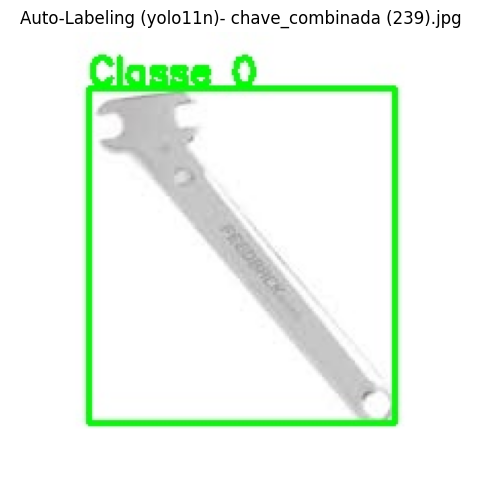

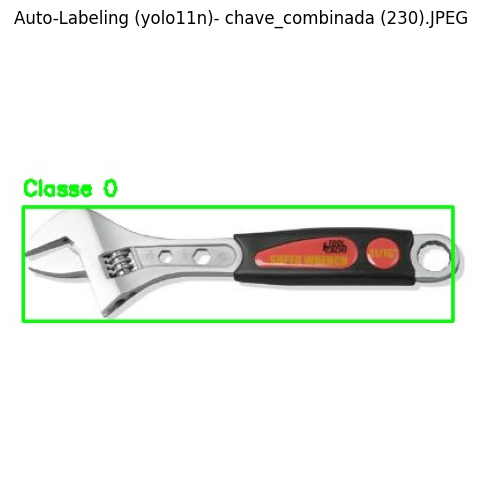

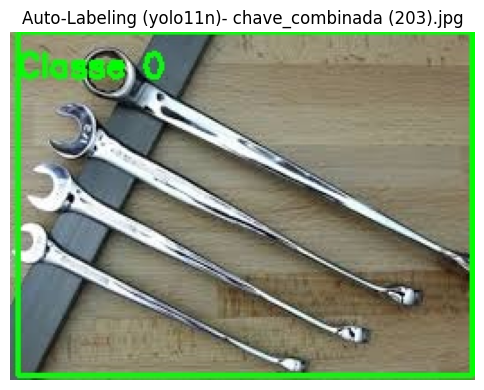

In [ ]:
mf.exibir_resultado_auto_labeling(pasta_processadas="dataset_bbox/auto-labeling_inicial", num_amostras=3)

## => As bounding boxes geradas ficaram bem erradas/estranhas, rss.... Isso vai dar trabalho!
Já era de se esperar! Como o YOLO base foi treinado no dataset geral do COCO (que tem coisas como pessoas, carros, cadeiras, garrafas), ele não tem a menor ideia do que é uma chave combinada. Ele tenta adivinhar com base em formas parecidas, o que geralmente resulta em caixas totalmente fora do lugar (ou ele pega um pedaço da bancada, ou ignora a chave).

Ainda bem que percebemos isso agora, antes de treinar o modelo com lixo <font color="orange">**("Garbage in, garbage out")**</font>.

❗ O processo de geração do auto-labeling pela função acima não ficou satisfatório.<br>
Utilizou-se um modelo base, no caso o Yolo11n,  para o `auto-labeling`.<br>
Para documentação, há o registro de alguns resultados acima, e acabamos optando por utilizar a solução da Roboflow (https://app.roboflow.com/), e desenhar as bounding boxes, <font color=mf.g_verde_claro><u>e segmentação por polígonos também</u></font>, que acabou sendo a melhor alternativa.<br>
O processo na sequência, já exibe os resultados após a importação das imagens processadas no Roboflow.

## 🎯 3.0 Utilizando o Roboflow

In [ ]:
%pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.7 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3


## 🔄 3.1 Exportar as imagens de treino e validação do Roboflow para um diretório local

In [ ]:
from roboflow import Roboflow

# Inicializar com a chave de API
rf = Roboflow(api_key="kVAO3w4YX0RTpvX5cA23")

# Conectar-se ao workspace e projeto
workspace = rf.workspace("plimas-workspace") # Nome do workspace no Roboflow
project = workspace.project("vac2")    # Nome do projeto

# Exportar diretamente os dados da seção de imagens sem gerar versão
workspace.search_export(
    query="*",                       # Trazer todas as imagens anotadas
    format="yolov8",                   # Formato desejado (ex: "coco" ou "yolov8")
    dataset="vac2",           # ID do projeto
    location="./dataset_exportado"   # Pasta de destino no computador
)

print(f"{mf.NEGRITO}{mf.VERDE}[SUCESSO] ✓ Dataset exportado sem gastar créditos de versão!{mf.RESET}")

loading Roboflow workspace...
loading Roboflow project...
Export started (id=ZNOzMluvTI). Polling for completion...
If this takes too long, you can check the export status at: https://api.roboflow.com/plimas-workspace/search/export/ZNOzMluvTI?api_key=YOUR_API_KEY


Extracting search export to /content/drive/MyDrive/Colab Notebooks/vision-auto-check/dataset_exportado: 100%|██████████| 294/294 [00:02<00:00, 137.03it/s]

Search export extracted to /content/drive/MyDrive/Colab Notebooks/vision-auto-check/dataset_exportado
[SUCESSO] ✓ Dataset exportado sem gastar créditos de versão!


# 🔎 3.2 Checagem aleatória de 3 **`Bounding boxes`** geradas. Apenas para certificações...

Inicialmente, como as imagens geradas não estavam separadas entre treino e validação, foram armazenadas num diretório específico ("./dataset_exportado") para na sequência serem distribuídas aos diretórios apropriados de treino e validação.

<font color="orange">E aqui, diferentemente da versão inicial (train_mix.ipynb), as detecções via segmentação por polígonos foi descartada, pois utilizaremos apenas as detecções via bounding boxes para a classe inicial, e todas as demais deste projeto.</font>

[INFO] Exibindo 3 amostras aleatórias da pasta 'train'


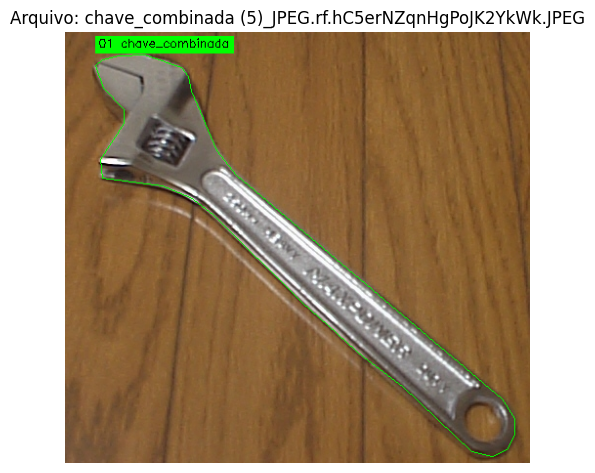

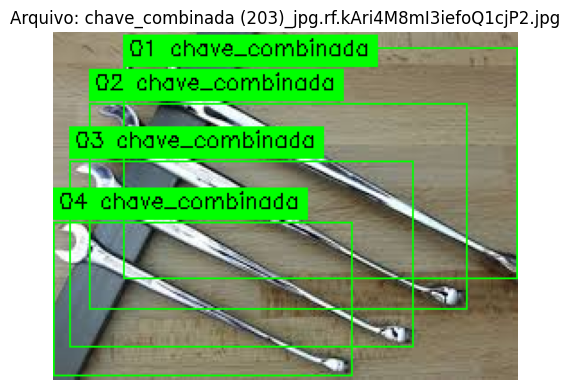

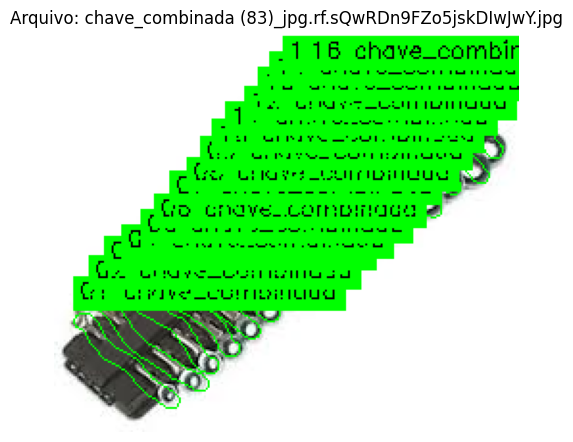

In [ ]:
# Exibe 3 imagens aleatórias com seus respectivos bounding boxes desenhados
mf.visualizar_amostras_labels(pasta_base="dataset_bbox", split="train", num_amostras=3, salvar_disco=False)

A abordagem que foi utilizada neste pipeline é a de validar a infraestrutura de ponta a ponta <font color="yellow">(pipeline MVP ou Proof of Concept)</font>.
Validaremos primeiramente toda a estrutura do pipeline com uma única classe e completando o ciclo, voltamos para a contemplação das demais classes.

Por que adotar esta estratégia?
  - Isolamento de Erros: Se algo der errado no treinamento, saberemos que o problema é no código do pipeline (hiperparâmetros, formato de diretórios, GPU, épocas), e não na complexidade de gerenciar múltiplos rótulos ou confusão entre classes.

  - Velocidade de Iteração: Treinar com apenas uma classe (chave_combinada) é muito mais rápido para testar se o modelo converge, se o data.yaml está conversando direito com o Ultralytics e se o Colab não vai cair por falta de memória.

  - Escalabilidade Tranquila: Com o pipeline testado e redondo, adicionar novas classes no futuro é apenas uma questão de atualizar o data.yaml e re-anotar as novas ferramentas. A estrutura do código permanece idêntica. ✔

## 🟢 Próxima etapa, o treinamento em si... (train_bbox.ipynb)

---
FIM